In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_excel('Тестовое_задание_Data_аналитик_ЦО_2025_2.xlsx', sheet_name="Данные для задачи 2", engine="calamine")
data

,Дата,Код товара,Количество продано,Розничная цена,Цена с учётом скидки
0,2024-06-01,3226300004,9,271,271.0
1,2024-06-02,3226300004,15,271,271.0
2,2024-06-03,3226300004,12,271,216.8
3,2024-06-04,3226300004,17,271,216.8
4,2024-06-05,3226300004,13,271,216.8
...,...,...,...,...,...
1215,2024-09-26,19000000363,38,2062,1340.3
1216,2024-09-27,19000000363,5,2062,2062.0
1217,2024-09-28,19000000363,14,2062,2062.0
1218,2024-09-29,19000000363,12,2062,2062.0


In [3]:
print(f"Строк: {len(data):,}")
print(f"SKU: {data['Код товара'].nunique():,}")

Строк: 1,220
SKU: 10


In [4]:
# Подготовка и контроль качества

def to_number(series):
    return pd.to_numeric(
        series.astype("string")
        .str.strip()
        .str.replace("\xa0", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

data["Дата"] = pd.to_datetime(data["Дата"], errors="coerce")
data["Код товара"] = data["Код товара"].astype("string").str.strip()
data["Количество продано"] = to_number(data["Количество продано"])
data["Розничная цена"] = to_number(data["Розничная цена"])
data["Цена с учётом скидки"] = to_number(data["Цена с учётом скидки"])

data = data.sort_values(["Код товара", "Дата"]).reset_index(drop=True)

invalid_rows = data.loc[
    data["Дата"].isna()
    | data["Код товара"].eq("")
    | data["Количество продано"].isna()
    | (data["Количество продано"] < 0)
    | data["Розничная цена"].isna()
    | (data["Розничная цена"] <= 0)
    | data["Цена с учётом скидки"].isna()
    | (data["Цена с учётом скидки"] <= 0)
].copy()

print("Некорректных строк:", len(invalid_rows))
display(invalid_rows.head())

data = data.drop(index=invalid_rows.index).copy()

sku_quality = (data.groupby("Код товара", as_index=False).agg(
        observations=("Дата", "size"),
        first_date=("Дата", "min"),
        last_date=("Дата", "max"),
        price_levels=("Цена с учётом скидки", "nunique"),
        min_observed_price=("Цена с учётом скидки", "min"),
        max_observed_price=("Цена с учётом скидки", "max"),
        avg_daily_qty=("Количество продано", "mean"),
    )
)

display(sku_quality)

Некорректных строк: 0


,Дата,Код товара,Количество продано,Розничная цена,Цена с учётом скидки


,Код товара,observations,first_date,last_date,price_levels,min_observed_price,max_observed_price,avg_daily_qty
0,14011400047,122,2024-06-01,2024-09-30,5,978.0,1630.0,13.721311
1,14012900005,122,2024-06-01,2024-09-30,5,794.95,1223.0,13.008197
2,15110900016,122,2024-06-01,2024-09-30,5,1035.3,1479.0,11.877049
3,15111300006,122,2024-06-01,2024-09-30,6,5237.05,8057.0,11.803279
4,15111300017,122,2024-06-01,2024-09-30,5,14547.0,19396.0,6.081967
5,19000000363,122,2024-06-01,2024-09-30,7,1340.3,2062.0,12.795082
6,19000013047,122,2024-06-01,2024-09-30,5,1870.2,3117.0,13.991803
7,19760336592,122,2024-06-01,2024-09-30,5,1971.2,2816.0,11.909836
8,3226300004,122,2024-06-01,2024-09-30,6,173.4,289.0,13.032787
9,3234800007,122,2024-06-01,2024-09-30,7,224.9,346.0,12.672131


### Промежуточный вывод: проверка данных
- пропусков и ошибочных строк нет
- у каждого товара 5-7 разных цен: скидки менялись ступенями от 10% до 40%

In [5]:
# Анализ продаж по уровням фактической цены
price_level_stats = (
    data.groupby(["Код товара", "Цена с учётом скидки"], as_index=False)
    .agg(
        days_at_price=("Дата", "size"),
        avg_daily_qty=("Количество продано", "mean"),
        median_daily_qty=("Количество продано", "median"),
        total_qty=("Количество продано", "sum"),
        retail_price=("Розничная цена", "median"),
    )
)

price_level_stats["discount_pct"] = 1 - price_level_stats["Цена с учётом скидки"] / price_level_stats["retail_price"]

price_level_stats = price_level_stats.sort_values(["Код товара", "Цена с учётом скидки"])

price_level_stats.head(10)

,Код товара,Цена с учётом скидки,days_at_price,avg_daily_qty,median_daily_qty,total_qty,retail_price,discount_pct
0,14011400047,978.0,4,34.25,33.5,137,1630.0,0.4
1,14011400047,1059.5,8,33.5,31.5,268,1630.0,0.35
2,14011400047,1141.0,8,24.5,25.0,196,1630.0,0.3
3,14011400047,1222.5,4,22.0,21.5,88,1630.0,0.25
4,14011400047,1630.0,98,10.05102,10.0,985,1630.0,0.0
5,14012900005,794.95,8,36.375,37.0,291,1223.0,0.35
6,14012900005,856.1,8,23.5,22.0,188,1223.0,0.3
7,14012900005,917.25,4,26.5,27.0,106,1223.0,0.25
8,14012900005,1039.55,4,16.25,18.0,65,1223.0,0.15
9,14012900005,1223.0,98,9.561224,9.0,937,1223.0,0.0


### Промежуточный вывод: продажи по уровням скидки
- без скидки товар продаётся примерно 10 штук в день (в среднем по 10 товарам)
- скидки 10-20% поднимают продажи в 1,4-1,7 раза
- скидки 25-30% поднимают продажи примерно в 2,5 раза
- скидки 35-40% поднимают продажи примерно в 3,5 раза
- то есть рост идёт скачками, самый заметный скачок на скидке 25%

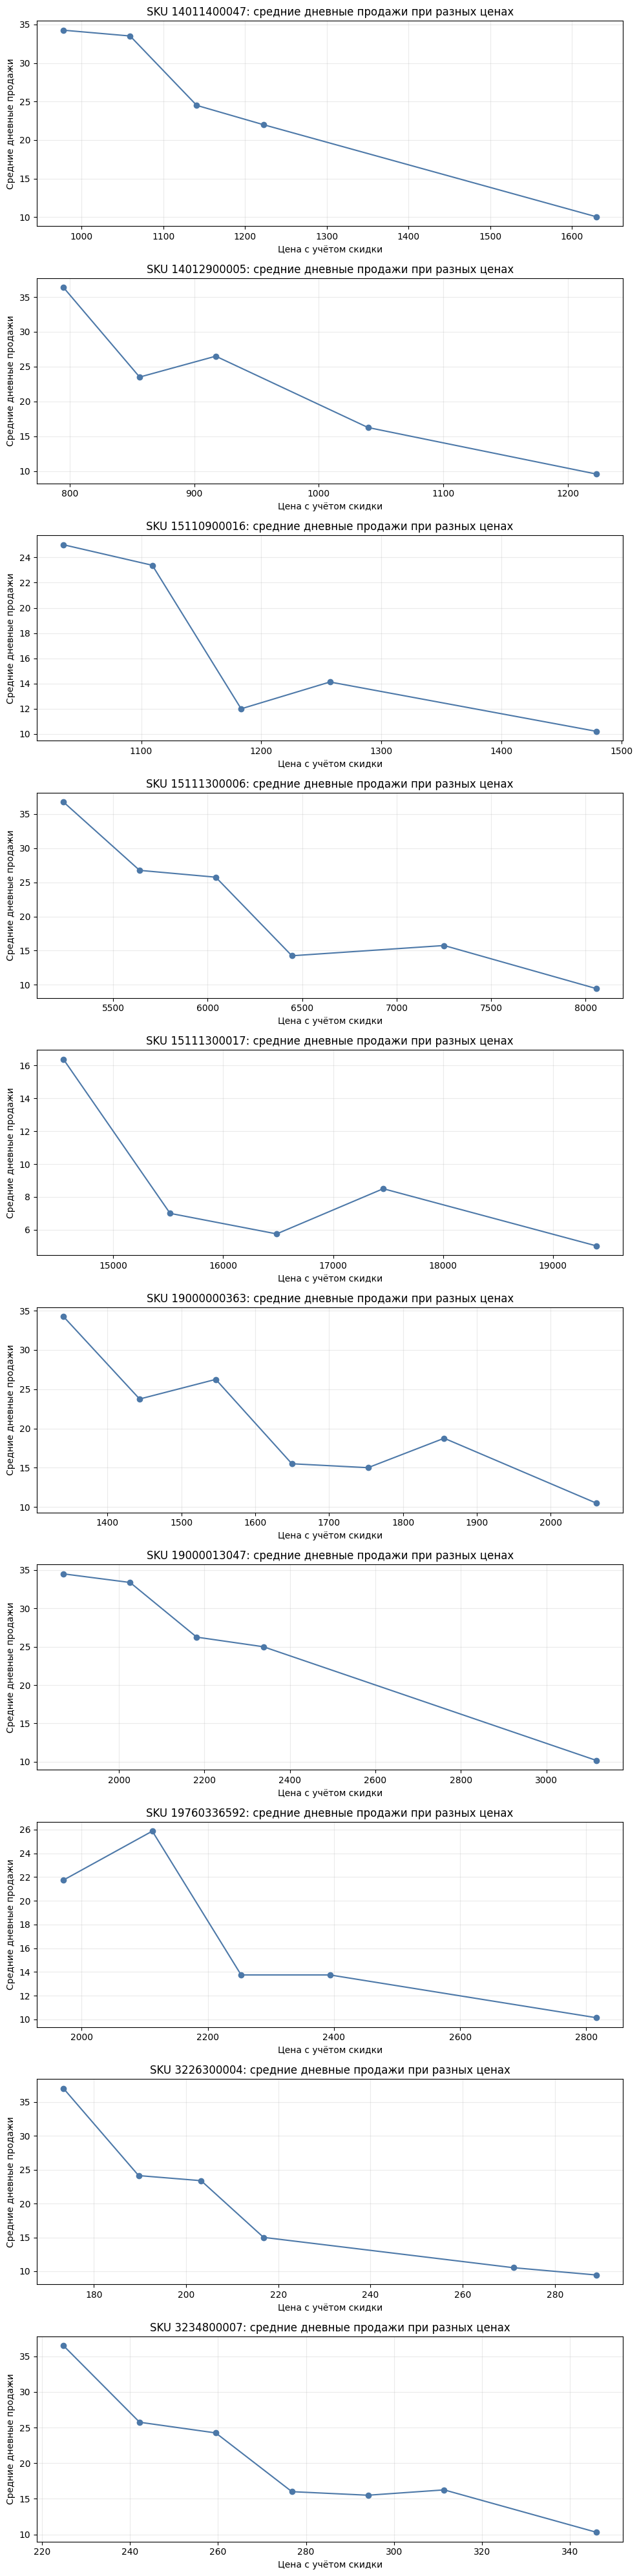

In [6]:
# График зависимости продаж от цены
sku_list = data["Код товара"].drop_duplicates().tolist()

fig, axes = plt.subplots(
    nrows=len(sku_list),
    ncols=1,
    figsize=(10, 4 * len(sku_list))
)

if len(sku_list) == 1:
    axes = [axes]

for ax, sku in zip(axes, sku_list):
    plot_df = price_level_stats.loc[
        price_level_stats["Код товара"].eq(sku)
    ].sort_values("Цена с учётом скидки")

    ax.plot(
        plot_df["Цена с учётом скидки"],
        plot_df["avg_daily_qty"],
        marker="o",
        color="#4C78A8"
    )
    ax.set_title(f"SKU {sku}: средние дневные продажи при разных ценах")
    ax.set_xlabel("Цена с учётом скидки")
    ax.set_ylabel("Средние дневные продажи")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Промежуточный вывод: графики
У всех 10 товаров одна и та же картина: чем ниже цена, тем выше продажи

In [7]:
# Текущий ценовой режим. Последний непрерывный период, в котором фактическая цена не менялась

def get_last_price_regime(group):
    group = group.sort_values("Дата").copy()

    group["price_changed"] = (
        group["Цена с учётом скидки"].ne(group["Цена с учётом скидки"].shift())
    )
    group["price_regime"] = group["price_changed"].cumsum()

    last_regime_id = group["price_regime"].max()
    current_regime = group.loc[group["price_regime"].eq(last_regime_id)].copy()

    last_row = current_regime.sort_values("Дата").iloc[-1]

    return pd.Series(
        {
            "current_price": last_row["Цена с учётом скидки"],
            "current_retail_price": last_row["Розничная цена"],
            "current_discount_pct": 1 - last_row["Цена с учётом скидки"] / last_row["Розничная цена"],
            "current_regime_start": current_regime["Дата"].min(),
            "current_regime_end": current_regime["Дата"].max(),
            "current_regime_days": len(current_regime),
            "current_avg_daily_qty": current_regime["Количество продано"].mean(),
            "current_total_qty": current_regime["Количество продано"].sum(),
        }
    )

current_regime = (
    data.groupby("Код товара", group_keys=False)
    .apply(get_last_price_regime, include_groups=False)
    .reset_index()
)
current_regime

,Код товара,current_price,current_retail_price,current_discount_pct,current_regime_start,current_regime_end,current_regime_days,current_avg_daily_qty,current_total_qty
0,14011400047,1630.0,1630,0.0,2024-09-27,2024-09-30,4,9.00,36
1,14012900005,1223.0,1223,0.0,2024-09-27,2024-09-30,4,8.75,35
2,15110900016,1479.0,1479,0.0,2024-09-27,2024-09-30,4,9.25,37
3,15111300006,8057.0,8057,0.0,2024-09-27,2024-09-30,4,12.00,48
4,15111300017,19396.0,19396,0.0,2024-09-27,2024-09-30,4,4.75,19
5,19000000363,2062.0,2062,0.0,2024-09-27,2024-09-30,4,10.50,42
6,19000013047,3117.0,3117,0.0,2024-09-27,2024-09-30,4,10.75,43
7,19760336592,2816.0,2816,0.0,2024-09-27,2024-09-30,4,8.25,33
8,3226300004,271.0,271,0.0,2024-09-27,2024-09-30,4,12.25,49
9,3234800007,346.0,346,0.0,2024-09-27,2024-09-30,4,11.25,45


### Промежуточный вывод: текущая цена
- В последние 4 дня (27.09.2024-30.09.2024) скидок нет ни на одном товаре. Сейчас продаётся примерно от 5 до 12 штук в день на товар. От этих значений считаем рост в два раза.

In [ ]:
# Оценка ценовой эластичности по log-log модели:
# log(продажи) = a + b * log(цена) + эффект дня недели, где b - ценовая эластичность.
# Отрицательный b означает, что более низкая цена исторически связана с большим объёмом продаж.
# https://mathcracker.com/ru/%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%8C-%D0%BB%D0%BE%D0%B3%D0%B0%D1%80%D0%B8%D1%84%D0%BC%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%BE%D0%B3%D0%BE-%D0%BB%D0%BE%D0%B3%D0%B0%D1%80%D0%B8%D1%84%D0%BC%D0%B0

def estimate_elasticity(group):
    group = group.loc[(group["Количество продано"] > 0) & (group["Цена с учётом скидки"] > 0)].copy()

    n_obs = len(group)
    n_price_levels = group["Цена с учётом скидки"].nunique()

    if n_obs < 30 or n_price_levels < 3:
        return pd.Series(
            {
                "elasticity": np.nan,
                "elasticity_se": np.nan,
                "model_r2": np.nan,
                "model_observations": n_obs,
                "model_price_levels": n_price_levels,
            }
        )

    y = np.log(group["Количество продано"].to_numpy())
    log_price = np.log(group["Цена с учётом скидки"].to_numpy())

    weekday_dummies = pd.get_dummies(
        group["Дата"].dt.dayofweek,
        prefix="weekday",
        drop_first=True,
        dtype=float,
    )

    X = np.column_stack(
        [
            np.ones(n_obs),
            log_price,
            weekday_dummies.to_numpy(),
        ]
    )

    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    y_pred = X @ beta
    residuals = y - y_pred

    ss_res = np.sum(residuals ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    degrees_of_freedom = n_obs - X.shape[1]
    if degrees_of_freedom > 0:
        sigma2 = ss_res / degrees_of_freedom
        covariance = sigma2 * np.linalg.pinv(X.T @ X)
        elasticity_se = np.sqrt(covariance[1, 1])
    else:
        elasticity_se = np.nan

    return pd.Series(
        {
            "elasticity": beta[1],
            "elasticity_se": elasticity_se,
            "model_r2": r2,
            "model_observations": n_obs,
            "model_price_levels": n_price_levels,
        }
    )

elasticity_results = (
    data.groupby("Код товара", group_keys=False)
    .apply(estimate_elasticity, include_groups=False)
    .reset_index()
)

elasticity_results

,Код товара,elasticity,elasticity_se,model_r2,model_observations,model_price_levels
0,14011400047,-2.760231,0.190271,0.682925,122.0,5.0
1,14012900005,-3.145081,0.228007,0.657127,122.0,5.0
2,15110900016,-2.484832,0.302443,0.448796,122.0,5.0
3,15111300006,-3.206071,0.294652,0.549962,122.0,6.0
4,15111300017,-4.124242,0.530846,0.354348,122.0,5.0
5,19000000363,-2.646878,0.244848,0.573068,122.0,7.0
6,19000013047,-2.836725,0.205006,0.669023,122.0,5.0
7,19760336592,-2.404075,0.305092,0.464476,122.0,5.0
8,3226300004,-2.738657,0.214814,0.607069,122.0,6.0
9,3234800007,-2.735274,0.301681,0.504018,122.0,7.0


### Промежуточный вывод: эластичность
- эластичность по всем товарам от −2,4 до −4,1 это значит, что снижение цены на 1% даёт рост продаж на 2,4-4,1%
- У `15111300017` (самая дорогая позиция) эластичность самая сильная, у `19760336592` самая слабая, модель объясняет от 35% до 68% разброса продаж, этого достаточно для оценки, но не для точного прогноза

In [ ]:
# Расчёт цены и скидки для цели «увеличить продажи в 2 раза»
recommendations = (
    sku_quality
    .merge(current_regime, on="Код товара", how="left")
    .merge(elasticity_results, on="Код товара", how="left")
)

# Формула:
# Q_target / Q_current = (P_target / P_current) ^ elasticity
# Для Q_target / Q_current = 2:
# P_target = P_current × 2^(1 / elasticity) - алгебраическая производная из log-log

valid_elasticity = recommendations["elasticity"] < 0

recommendations["theoretical_target_price"] = np.where(
    valid_elasticity,
    recommendations["current_price"] * np.power(
        2,
        1 / recommendations["elasticity"]
    ),
    np.nan
)

recommendations["theoretical_total_discount_pct"] = (
    1
    - recommendations["theoretical_target_price"]
    / recommendations["current_retail_price"]
)

recommendations["additional_discount_pp"] = (
    recommendations["theoretical_total_discount_pct"]
    - recommendations["current_discount_pct"]
)

recommendations["within_historical_price_range"] = (
    recommendations["theoretical_target_price"]
    >= recommendations["min_observed_price"]
) & (
    recommendations["theoretical_target_price"]
    <= recommendations["max_observed_price"]
)

recommendations["recommendation_status"] = np.select(
    [
        recommendations["elasticity"].isna(),
        recommendations["elasticity"] >= 0,
        ~recommendations["within_historical_price_range"],
        recommendations["within_historical_price_range"],
    ],
    [
        "Недостаточно данных для оценки эластичности",
        "Исторические данные не подтверждают рост продаж при снижении цены",
        "Цена для удвоения продаж выходит за исторический диапазон: нужен тест",
        "Можно рекомендовать скидку как гипотезу для A/B-теста",
    ],
    default="Требуется проверка",
)

recommendations[[
    "Код товара",
    "current_price",
    "current_retail_price",
    "current_discount_pct",
    "current_avg_daily_qty",
    "elasticity",
    "elasticity_se",
    "model_r2",
    "theoretical_target_price",
    "theoretical_total_discount_pct",
    "additional_discount_pp",
    "within_historical_price_range",
    "recommendation_status",
]].sort_values("Код товара")

,Код товара,current_price,current_retail_price,current_discount_pct,current_avg_daily_qty,elasticity,elasticity_se,model_r2,theoretical_target_price,theoretical_total_discount_pct,additional_discount_pp,within_historical_price_range,recommendation_status
0,14011400047,1630.0,1630,0.0,9.00,-2.760231,0.190271,0.682925,1268.025222,0.222070,0.222070,True,Можно рекомендовать скидку как гипотезу для A/...
1,14012900005,1223.0,1223,0.0,8.75,-3.145081,0.228007,0.657127,981.096904,0.197795,0.197795,True,Можно рекомендовать скидку как гипотезу для A/...
2,15110900016,1479.0,1479,0.0,9.25,-2.484832,0.302443,0.448796,1118.976992,0.243423,0.243423,True,Можно рекомендовать скидку как гипотезу для A/...
3,15111300006,8057.0,8057,0.0,12.00,-3.206071,0.294652,0.549962,6490.521839,0.194424,0.194424,True,Можно рекомендовать скидку как гипотезу для A/...
4,15111300017,19396.0,19396,0.0,4.75,-4.124242,0.530846,0.354348,16395.391822,0.154702,0.154702,True,Можно рекомендовать скидку как гипотезу для A/...
5,19000000363,2062.0,2062,0.0,10.50,-2.646878,0.244848,0.573068,1586.932556,0.230392,0.230392,True,Можно рекомендовать скидку как гипотезу для A/...
6,19000013047,3117.0,3117,0.0,10.75,-2.836725,0.205006,0.669023,2441.282047,0.216785,0.216785,True,Можно рекомендовать скидку как гипотезу для A/...
7,19760336592,2816.0,2816,0.0,8.25,-2.404075,0.305092,0.464476,2110.649283,0.250480,0.250480,True,Можно рекомендовать скидку как гипотезу для A/...
8,3226300004,271.0,271,0.0,12.25,-2.738657,0.214814,0.607069,210.402295,0.223608,0.223608,True,Можно рекомендовать скидку как гипотезу для A/...
9,3234800007,346.0,346,0.0,11.25,-2.735274,0.301681,0.504018,268.547620,0.223851,0.223851,True,Можно рекомендовать скидку как гипотезу для A/...


### Промежуточный вывод: цена для роста в 2 раза
Нужная цена считается по формуле: текущая цена * 2^(1 / эластичность) чем выше эластичность, тем меньшая скидка нужна

In [ ]:
# Финальная таблица для выводов

final_columns = [
    "Код товара",
    "current_regime_start",
    "current_regime_end",
    "current_regime_days",
    "current_avg_daily_qty",
    "current_retail_price",
    "current_price",
    "current_discount_pct",
    "price_levels",
    "elasticity",
    "elasticity_se",
    "model_r2",
    "theoretical_target_price",
    "theoretical_total_discount_pct",
    "additional_discount_pp",
    "min_observed_price",
    "max_observed_price",
    "within_historical_price_range",
    "recommendation_status",
]

final_recommendations = recommendations[final_columns].sort_values(["recommendation_status", "additional_discount_pp"], ascending=False)
final_recommendations

,Код товара,current_regime_start,current_regime_end,current_regime_days,current_avg_daily_qty,current_retail_price,current_price,current_discount_pct,price_levels,elasticity,elasticity_se,model_r2,theoretical_target_price,theoretical_total_discount_pct,additional_discount_pp,min_observed_price,max_observed_price,within_historical_price_range,recommendation_status
7,19760336592,2024-09-27,2024-09-30,4,8.25,2816,2816.0,0.0,5,-2.404075,0.305092,0.464476,2110.649283,0.250480,0.250480,1971.2,2816.0,True,Можно рекомендовать скидку как гипотезу для A/...
2,15110900016,2024-09-27,2024-09-30,4,9.25,1479,1479.0,0.0,5,-2.484832,0.302443,0.448796,1118.976992,0.243423,0.243423,1035.3,1479.0,True,Можно рекомендовать скидку как гипотезу для A/...
5,19000000363,2024-09-27,2024-09-30,4,10.50,2062,2062.0,0.0,7,-2.646878,0.244848,0.573068,1586.932556,0.230392,0.230392,1340.3,2062.0,True,Можно рекомендовать скидку как гипотезу для A/...
9,3234800007,2024-09-27,2024-09-30,4,11.25,346,346.0,0.0,7,-2.735274,0.301681,0.504018,268.547620,0.223851,0.223851,224.9,346.0,True,Можно рекомендовать скидку как гипотезу для A/...
8,3226300004,2024-09-27,2024-09-30,4,12.25,271,271.0,0.0,6,-2.738657,0.214814,0.607069,210.402295,0.223608,0.223608,173.4,289.0,True,Можно рекомендовать скидку как гипотезу для A/...
0,14011400047,2024-09-27,2024-09-30,4,9.00,1630,1630.0,0.0,5,-2.760231,0.190271,0.682925,1268.025222,0.222070,0.222070,978.0,1630.0,True,Можно рекомендовать скидку как гипотезу для A/...
6,19000013047,2024-09-27,2024-09-30,4,10.75,3117,3117.0,0.0,5,-2.836725,0.205006,0.669023,2441.282047,0.216785,0.216785,1870.2,3117.0,True,Можно рекомендовать скидку как гипотезу для A/...
1,14012900005,2024-09-27,2024-09-30,4,8.75,1223,1223.0,0.0,5,-3.145081,0.228007,0.657127,981.096904,0.197795,0.197795,794.95,1223.0,True,Можно рекомендовать скидку как гипотезу для A/...
3,15111300006,2024-09-27,2024-09-30,4,12.00,8057,8057.0,0.0,6,-3.206071,0.294652,0.549962,6490.521839,0.194424,0.194424,5237.05,8057.0,True,Можно рекомендовать скидку как гипотезу для A/...
4,15111300017,2024-09-27,2024-09-30,4,4.75,19396,19396.0,0.0,5,-4.124242,0.530846,0.354348,16395.391822,0.154702,0.154702,14547.0,19396.0,True,Можно рекомендовать скидку как гипотезу для A/...


### Промежуточный вывод: итоговая таблица
- для всех 10 товаров расчётная цена лежит внутри уже встречавшегося диапазона цен
- значит, модель не уходит в область, где данных нет

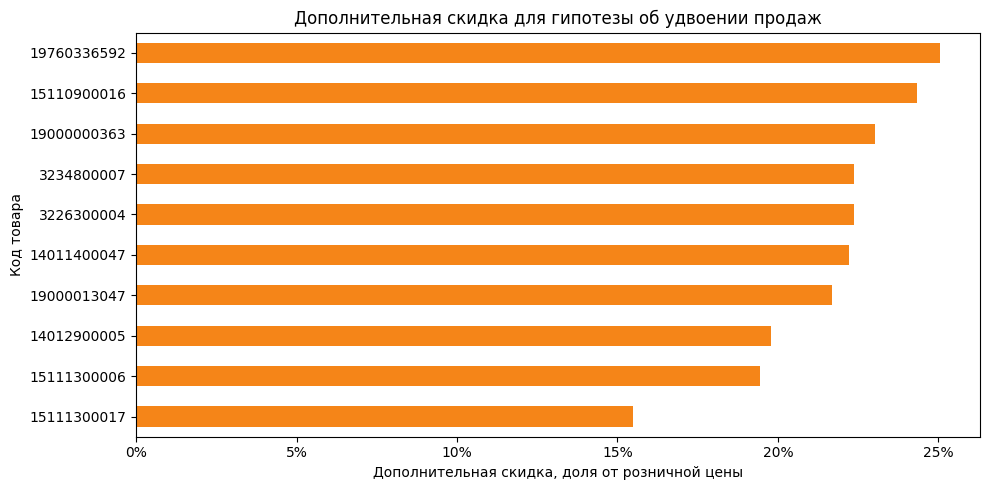

In [11]:
# Визуализация рекомендуемых скидок
plot_df = final_recommendations.loc[final_recommendations["recommendation_status"].eq("Можно рекомендовать скидку как гипотезу для A/B-теста")].copy()

if len(plot_df) > 0:
    plot_df = plot_df.sort_values("additional_discount_pp", ascending=True)

    ax = plot_df.plot(
        kind="barh",
        x="Код товара",
        y="additional_discount_pp",
        figsize=(10, 5),
        legend=False,
        color="#F58518",
    )

    ax.set_title("Дополнительная скидка для гипотезы об удвоении продаж")
    ax.set_xlabel("Дополнительная скидка, доля от розничной цены")
    ax.set_ylabel("Код товара")
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
    plt.tight_layout()
    plt.show()
else:
    print("Нет SKU с рекомендацией в пределах исторического диапазона цен.")

### Промежуточный вывод: проверка модели по истории
- на скидках 10-20% продажи росли в 1,2-1,8 раза, до двукратного роста не доходили
- на скидке 25% продажи выросли в 2,2-3,3 раза у всех 10 товаров
- на скидках 35-40% рост был около 3,3-3,9 раза
- модель показывает плавную зависимость, а в данных рост идёт скачком около 25%, поэтому модель занижает нужную скидку
- каждый уровень скидки держался только 4-8 дней, так что данных мало

In [12]:
# Проверка модели по истории: во сколько раз реально росли продажи на каждом уровне скидки.
# Базой считаем средние дневные продажи в дни без скидки.
history = data.copy()
history["discount_level"] = (1 - history["Цена с учётом скидки"] / history["Розничная цена"]).round(2)

uplift = (
    history.groupby(["Код товара", "discount_level"], as_index=False)
    .agg(days=("Дата", "size"), avg_daily_qty=("Количество продано", "mean"))
)

base_qty = uplift.loc[uplift["discount_level"].eq(0)].set_index("Код товара")["avg_daily_qty"]
uplift["uplift_x"] = (uplift["avg_daily_qty"] / uplift["Код товара"].map(base_qty)).astype(float)

uplift_table = uplift.pivot(index="Код товара", columns="discount_level", values="uplift_x")
uplift_table.columns = [f"{c:.0%}" for c in uplift_table.columns]
print("Во сколько раз выросли продажи по сравнению с днями без скидки:")
print(uplift_table.round(2).to_string())
print()
skidka_days = uplift.loc[uplift["discount_level"] > 0, "days"]
print(f"Каждый уровень скидки держался от {int(skidka_days.min())} до {int(skidka_days.max())} дней")

Во сколько раз выросли продажи по сравнению с днями без скидки:
              0%   10%   15%   20%   25%   30%   35%   40%
Код товара                                                
14011400047  1.0   NaN   NaN   NaN  2.19  2.44  3.33  3.41
14012900005  1.0   NaN  1.70   NaN  2.77  2.46  3.80   NaN
15110900016  1.0   NaN  1.38  1.17  2.29  2.45   NaN   NaN
15111300006  1.0  1.67   NaN  1.51  2.73  2.83  3.89   NaN
15111300017  1.0  1.69  1.15  1.39  3.26   NaN   NaN   NaN
19000000363  1.0  1.79  1.43  1.48  2.50  2.27  3.27   NaN
19000013047  1.0   NaN   NaN   NaN  2.46  2.58  3.28  3.39
19760336592  1.0   NaN  1.36  1.36  2.55  2.14   NaN   NaN
3226300004   1.0   NaN   NaN  1.47  2.29  2.36   NaN  3.62
3234800007   1.0  1.58  1.51  1.55  2.36  2.50  3.55   NaN

Каждый уровень скидки держался от 4 до 8 дней


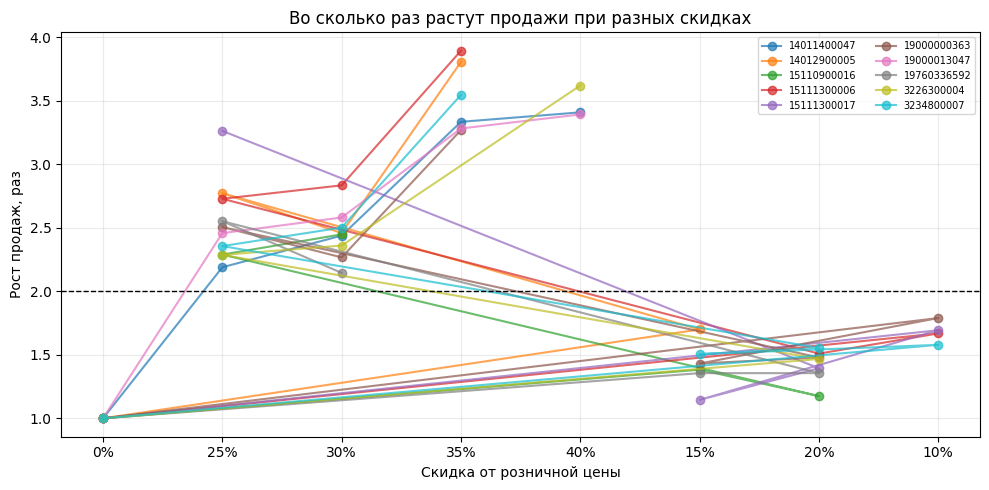

In [13]:
# График: рост продаж на каждом уровне скидки. Пунктир - цель в 2 раза.
fig, ax = plt.subplots(figsize=(10, 5))

for sku, row in uplift_table.iterrows():
    row = row.dropna()
    ax.plot(row.index, row.values, marker="o", alpha=0.7, label=str(sku))

ax.axhline(2, color="black", linestyle="--", linewidth=1)
ax.set_title("Во сколько раз растут продажи при разных скидках")
ax.set_xlabel("Скидка от розничной цены")
ax.set_ylabel("Рост продаж, раз")
ax.grid(alpha=0.25)
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

### Промежуточный вывод: итоговое предложение
- для всех 10 товаров в истории скидка 25% уже давала рост продаж минимум в 2 раза
- поэтому предлагаем 25% вместо расчёта модели (15,5-25%)
- расчёт модели оставили в таблице для сравнения

In [14]:
# Итоговое предложение: берём минимальную скидку, на которой в истории продажи уже выросли хотя бы в 2 раза.
# Если такой скидки в истории нет, берём расчёт модели.
reached = (
    uplift.loc[uplift["uplift_x"] >= 2]
    .sort_values(["Код товара", "discount_level"])
    .groupby("Код товара", as_index=False)
    .first()[["Код товара", "discount_level", "uplift_x", "days"]]
    .rename(columns={
        "discount_level": "historical_discount",
        "uplift_x": "historical_uplift",
        "days": "historical_days",
    })
)

final_recommendations = final_recommendations.merge(reached, on="Код товара", how="left")

final_recommendations["proposed_discount"] = (
    final_recommendations["historical_discount"]
    .fillna(final_recommendations["theoretical_total_discount_pct"])
    .astype(float)
)
final_recommendations["proposed_price"] = (
    final_recommendations["current_retail_price"] * (1 - final_recommendations["proposed_discount"])
)

proposal_table = final_recommendations[[
    "Код товара", "current_price", "theoretical_total_discount_pct",
    "historical_discount", "historical_uplift", "proposed_discount", "proposed_price"
]].sort_values("Код товара").copy()

proposal_table["theoretical_total_discount_pct"] = proposal_table["theoretical_total_discount_pct"].map("{:.1%}".format)
proposal_table["historical_discount"] = proposal_table["historical_discount"].map("{:.0%}".format)
proposal_table["historical_uplift"] = proposal_table["historical_uplift"].map("{:.2f}".format)
proposal_table["proposed_discount"] = proposal_table["proposed_discount"].map("{:.0%}".format)
proposal_table["current_price"] = proposal_table["current_price"].map("{:,.0f}".format)
proposal_table["proposed_price"] = proposal_table["proposed_price"].map("{:,.0f}".format)

print(proposal_table.to_string(index=False))

 Код товара current_price theoretical_total_discount_pct historical_discount historical_uplift proposed_discount proposed_price
14011400047         1,630                          22.2%                 25%              2.19               25%          1,222
14012900005         1,223                          19.8%                 25%              2.77               25%            917
15110900016         1,479                          24.3%                 25%              2.29               25%          1,109
15111300006         8,057                          19.4%                 25%              2.73               25%          6,043
15111300017        19,396                          15.5%                 25%              3.26               25%         14,547
19000000363         2,062                          23.0%                 25%              2.50               25%          1,546
19000013047         3,117                          21.7%                 25%              2.46          

### Промежуточный вывод: график скидок
- нужная скидка получилась от 15,5% до 25% от розничной цены
- меньше всего - для `15111300017`, больше всего - для `19760336592`

In [15]:
всего_sku = len(final_recommendations)

# Что показывает история на соседних уровнях скидки
рост_при_20 = uplift.loc[uplift["discount_level"].eq(0.20), "uplift_x"]
рост_при_25 = uplift.loc[uplift["discount_level"].eq(0.25), "uplift_x"]
sku_с_25 = int(final_recommendations["historical_discount"].eq(0.25).sum())

note = f"""
Проанализировано {всего_sku} товаров.

По модели для роста продаж в 2 раза нужна скидка от
{final_recommendations["theoretical_total_discount_pct"].min():.1%} до
{final_recommendations["theoretical_total_discount_pct"].max():.1%}.

В истории картина другая. При скидке 20% продажи росли не больше чем в
{рост_при_20.max():.2f} раза, а при скидке 25% у всех товаров - не меньше чем в
{рост_при_25.min():.2f} раза (в среднем в {рост_при_25.mean():.2f} раза).
Рост идёт скачком, а модель сглаживает его и занижает нужную скидку.

Поэтому предлагаем скидку 25% от розничной цены для {sku_с_25} товаров из {всего_sku}.
Каждый уровень скидки в истории держался всего 4-8 дней, поэтому сначала
нужен тест на части товаров. Закупочных цен в данных нет, поэтому прибыль
при такой скидке нужно проверить отдельно.
"""

print(note)


Проанализировано 10 товаров.

По модели для роста продаж в 2 раза нужна скидка от
15.5% до
25.0%.

В истории картина другая. При скидке 20% продажи росли не больше чем в
1.55 раза, а при скидке 25% у всех товаров - не меньше чем в
2.19 раза (в среднем в 2.54 раза).
Рост идёт скачком, а модель сглаживает его и занижает нужную скидку.

Поэтому предлагаем скидку 25% от розничной цены для 10 товаров из 10.
Каждый уровень скидки в истории держался всего 4-8 дней, поэтому сначала
нужен тест на части товаров. Закупочных цен в данных нет, поэтому прибыль
при такой скидке нужно проверить отдельно.



## Итог по заданию 2
- по модели для роста продаж в 2 раза нужна скидка от 15,5% до 25%, в среднем около 22%
- проверка по истории показала, что модель занижает скидку: на 20% продажи росли максимум в 1,6 раза, а на 25% - минимум в 2,2 раза
- предложение: скидка 25% от розничной цены на всех 10 товарах, в истории она давала рост в 2,2-3,3 раза
- скидку выше 25% пока не нужно: цель в 2 раза достигается уже на ней
- каждый уровень скидки держался 4-8 дней, поэтому сначала нужен тест на части товаров
- закупки в данных нет, а скидка 25% при росте продаж в 2 раза сохраняет прибыль только у товаров с маржой от цены не ниже 50%, это надо проверить до запуска